# 01 - Dataset & Feature Selection
Fetch SPY OHLCV, pick which features go into the model, build the target, and save the resulting (X, y) dataset to disk for the next notebook.

Re-run this notebook whenever you want to try a different feature set or target horizon.

## Setup

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import matplotlib.pyplot as plt

from src.data_loader import fetch_ohlcv
from src.target import ForwardLogReturnTarget
from src.dataset import build_dataset
from src.features import (
    FeatureEngine, available_features,
    LogReturnFeature, RollingZScoreFeature, RangePositionFeature,
    RealizedVolatilityFeature, RelativeVolumeFeature, SignedVolumeFlowFeature,
    SessionTimeSinFeature, SessionTimeCosFeature, DayOfWeekSinFeature, DayOfWeekCosFeature,
)

DATA_DIR = PROJECT_ROOT / 'data'
DATA_DIR.mkdir(exist_ok=True)

## 1. Fetch data
Edit `TICKER` / `INTERVAL` / `PERIOD` to try other symbols or granularities.

In [2]:
TICKER = 'SPY'
INTERVAL = '5m'
PERIOD = '60d'

df = fetch_ohlcv(TICKER, INTERVAL, PERIOD)
print(df.shape)
df.tail()

(4661, 5)


,open,high,low,close,volume
timestamp,,,,,
2026-11-25 15:35:00-05:00,714.640015,714.909973,713.590027,714.010010,739523
2026-11-25 15:40:00-05:00,714.005005,715.169983,713.770020,715.169983,1379353
2026-11-25 15:45:00-05:00,715.190002,716.890015,714.679993,716.525024,1281274
2026-11-25 15:50:00-05:00,716.570007,717.739990,716.500000,716.799988,1406073
2026-11-25 15:55:00-05:00,716.739990,718.409973,716.150024,716.710022,3693325


## 2. Choose features
This is the knob to turn when experimenting: comment/uncomment or add `Feature` instances.
`available_features()` lists every `Feature` class currently registered in `src/features/` (new ones just need `@register` — no engine changes needed).

In [3]:
print('Registered feature classes:', list(available_features().keys()))

Registered feature classes: ['RollingZScoreFeature', 'RangePositionFeature', 'LogReturnFeature', 'SessionTimeSinFeature', 'SessionTimeCosFeature', 'DayOfWeekSinFeature', 'DayOfWeekCosFeature', 'RealizedVolatilityFeature', 'RelativeVolumeFeature', 'SignedVolumeFlowFeature']


In [4]:
selected_features = [
    LogReturnFeature(horizon=1),
    LogReturnFeature(horizon=5),
    LogReturnFeature(horizon=15),
    RollingZScoreFeature(window=30),
    RangePositionFeature(window=30),
    RealizedVolatilityFeature(window=30),
    RelativeVolumeFeature(window=30),
    SignedVolumeFlowFeature(),
    SessionTimeSinFeature(),
    SessionTimeCosFeature(),
    DayOfWeekSinFeature(),
    DayOfWeekCosFeature(),
]

engine = FeatureEngine(selected_features)
engine.feature_names

['log_return_1',
 'log_return_5',
 'log_return_15',
 'zscore_30',
 'range_pos_30',
 'realized_vol_30',
 'rel_volume_30',
 'signed_volume',
 'session_time_sin',
 'session_time_cos',
 'day_of_week_sin',
 'day_of_week_cos']

## 3. Target
`HORIZON` = how many bars ahead to predict (k in the spec).

In [5]:
HORIZON = 5
target = ForwardLogReturnTarget(horizon=HORIZON)

## 4. Build the dataset
Drops rows invalid due to feature warm-up or missing future price, keeping chronological order.

In [6]:
X, y = build_dataset(df, engine, target)
print('X:', X.shape, ' y:', y.shape)
X.join(y).head()

X: (4625, 12)  y: (4625,)


,log_return_1,log_return_5,log_return_15,zscore_30,range_pos_30,realized_vol_30,rel_volume_30,signed_volume,session_time_sin,session_time_cos,day_of_week_sin,day_of_week_cos,fwd_log_return_5
timestamp,,,,,,,,,,,,,
2026-09-02 12:05:00-04:00,-0.000078,0.000117,0.000405,0.598137,0.866983,0.000488,0.361215,-106702.0,0.600742,-0.799443,0.587785,-0.809017,-0.000836
2026-09-02 12:10:00-04:00,-0.000065,0.000849,0.000496,0.503192,0.855109,0.000486,0.321116,-89799.0,0.534466,-0.845190,0.587785,-0.809017,-0.000787
2026-09-02 12:15:00-04:00,-0.000314,0.000255,0.000026,0.205930,0.778618,0.000453,0.432393,-115240.0,0.464723,-0.885456,0.587785,-0.809017,-0.000980
2026-09-02 12:20:00-04:00,-0.000608,-0.001228,-0.000595,-0.482940,0.593506,0.000468,0.424541,-111155.0,0.391967,-0.919979,0.587785,-0.809017,-0.000177
2026-09-02 12:25:00-04:00,-0.000177,-0.001241,-0.000886,-0.888189,0.435795,0.000453,0.617633,-158043.0,0.316668,-0.948536,0.587785,-0.809017,0.000379


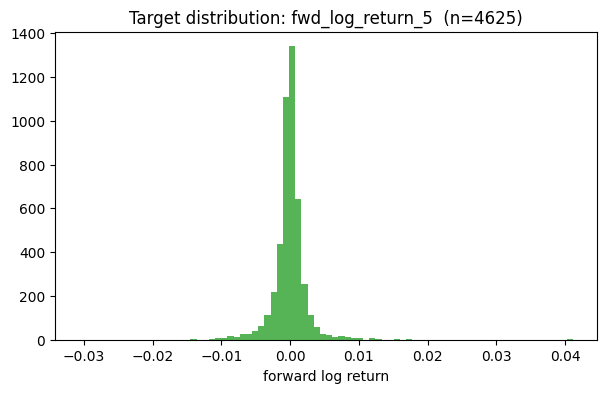

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(y, bins=80, color='#2ca02c', alpha=0.8)
ax.set_title(f'Target distribution: {target.name}  (n={len(y)})')
ax.set_xlabel('forward log return')
plt.show()

## 5. Persist for the next notebook

In [8]:
dataset = X.join(y)
dataset.to_parquet(DATA_DIR / 'dataset.parquet')
print(f"Saved {dataset.shape} to {DATA_DIR / 'dataset.parquet'}")

Saved (4625, 13) to /Users/user/Desktop/python/quant/CNN-agent/data/dataset.parquet


In [9]:
# Keep raw close price (full series, not just feature rows) so later notebooks
# can plot predictions directly against price.
df[['close']].to_parquet(DATA_DIR / 'raw_close.parquet')
print(f"Saved raw close price to {DATA_DIR / 'raw_close.parquet'}")

Saved raw close price to /Users/user/Desktop/python/quant/CNN-agent/data/raw_close.parquet
